Dataset loaded successfully!
Dataset shape: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

--- Clustering Evaluation ---
Metric                                K-Means    EM (GMM)
Silhouette (higher is better)           0.555       0.554
Davies-Bouldin (lower is better)        0.572       0.576

Agreement between algorithms (ARI): 0.956


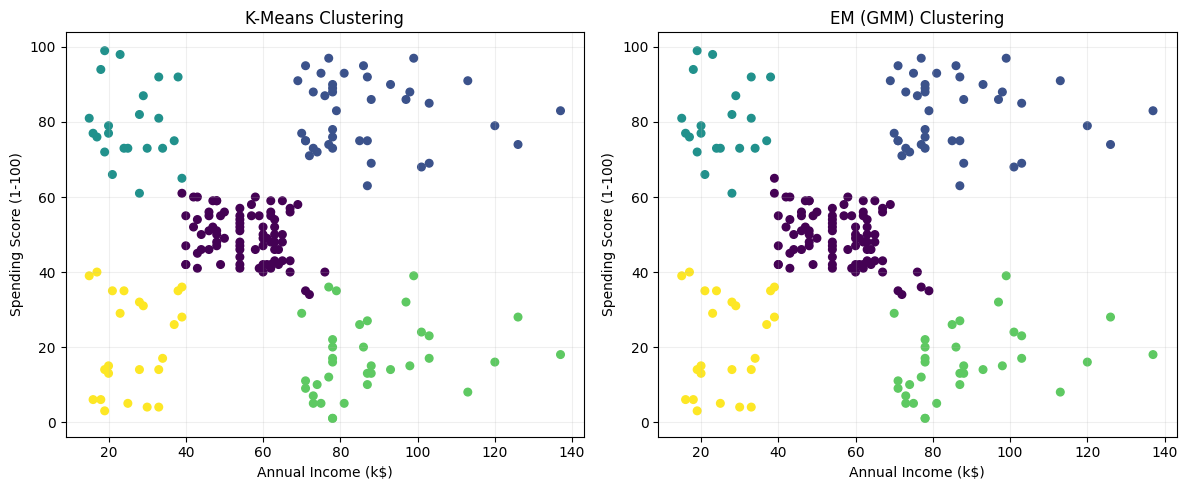

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

file_id = "1H3YQ-qh_KEilauPn56jNbLs6ilQ5m26o"
file_url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(file_url)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 5
kmeans = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=42
)
km_labels = kmeans.fit_predict(X_scaled)

gmm = GaussianMixture(
    n_components=k,
    random_state=42
)
gmm.fit(X_scaled)
em_labels = gmm.predict(X_scaled)

print("\n--- Clustering Evaluation ---")
print(f"{'Metric':<35}{'K-Means':>10}{'EM (GMM)':>12}")
print(
    f"{'Silhouette (higher is better)':<35}"
    f"{silhouette_score(X_scaled, km_labels):>10.3f}"
    f"{silhouette_score(X_scaled, em_labels):>12.3f}"
)
print(
    f"{'Davies-Bouldin (lower is better)':<35}"
    f"{davies_bouldin_score(X_scaled, km_labels):>10.3f}"
    f"{davies_bouldin_score(X_scaled, em_labels):>12.3f}"
)
print(
    "\nAgreement between algorithms (ARI):",
    round(adjusted_rand_score(km_labels, em_labels), 3)
)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, labels, title in zip(
    ax,
    [km_labels, em_labels],
    ["K-Means Clustering", "EM (GMM) Clustering"]
):
    a.scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=labels,
        cmap="viridis",
        s=30
    )
    a.set_title(title)
    a.set_xlabel("Annual Income (k$)")
    a.set_ylabel("Spending Score (1-100)")
    a.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("clusters.png", dpi=300, bbox_inches="tight")
plt.show()